# Coding Assignment 11: Clustering Token Representations

---
## What You'll Learn
- Trace the supplied k-means assignment and update steps
- Understand spectral clustering via the graph Laplacian
- Distinguish numerical clusters from evidence of learned meaning
- **Milestone:** compare artificial attention patterns, then visualize token-vector clusters in 2D PCA space

## Estimated Time: 2–3 hours
---


## Start here: how to work through this notebook

You do not need to remember an earlier programming course. Work one small step
at a time. The mathematics is the goal; the programming examples are here to
help you express it.

1. Save your own copy of the notebook. A **cell** is one block of text or code.
   Click a code cell and press **Shift+Enter** to run it. Run cells from the top
   down: later cells use names created by earlier cells.
2. Run the setup cell first. `import numpy as np` makes NumPy's array tools
   available under the short name `np`.
3. Read the explanation and run the small practice example before attempting
   the corresponding task. Practice cells are supplied; you may experiment
   with them, but restore them before the final run.
4. Edit only the requested task or response. `#` begins a comment. `pass` is a
   placeholder that does nothing; a function ending at `pass` returns `None`
   (no result). Replace it with your calculation and a `return` statement.
5. Running a cell containing `def` stores the function; it does not call it.
   After editing the definition, run that cell again, then run its check cell.
   A successful `assert` may print nothing. A skipped check is not a pass:
   if a result is still `None`, the task is unfinished.
6. If a check fails, stop there. Read the last line of the error, print the
   relevant array's `.shape`, and fix this task before running cells that need it.
   Errors below an unfinished task are expected and are not separate failures.
7. Save, restart the kernel/runtime (the Python session), and run everything
   from the beginning once your work is complete. This catches accidental use
   of a value left over from an earlier attempt.

**Reading code:** `=` stores a value; `==` compares values; `@` multiplies
matrices; `*` multiplies entries or scales an array; `**2` squares entries.
Python indices start at **0**: mathematical entry $a_{1,1}$ is `A[0, 0]`.
`A.shape` is `(number_of_rows, number_of_columns)`, `A.ndim` counts dimensions,
and `A.T` transposes a matrix. An ordinary vector has shape `(n,)`.

**If you get stuck:** record the function name, the smallest input that fails,
its shape, the expected mathematical result, and the last line of the error.
Include these when asking for help. You do not need to rewrite the whole cell.

**Plan your time:** if Python is new to you, allow extra time beyond the
headline estimate and work in several short sessions. Start with setup and
the practice example; then finish one task at a time.

More worked examples and an error-message checklist: [Python and NumPy help](`mt_utils.py` / `mini_transformer.py` in this folder).


### Files, dependencies, and what you are expected to edit

Save this notebook and download the supplied helper
`mt_utils.py` (same folder as this notebook)
using GitHub's **Download raw file** button. Put it beside the notebook; in
Colab, upload it through the Files panel before setup. This is a read-only
instructor helper for making reproducible toy data. Do not edit or submit it.
If Python cannot find it, check the filename and working folder first.

The notebook uses NumPy and Matplotlib. Colab normally provides both. Locally, install missing packages in
the notebook's environment with `%pip install numpy matplotlib`, then
restart the kernel. Run this installation command only if setup reports a
missing package.

Read the task guides below to distinguish **supplied demonstrations** from
**code you edit**. For a supplied implementation, run the code and trace its intermediate
values. Only fill placeholders explicitly identified as your task. Keep function names and arguments unchanged.
Write your observations in a Markdown cell below each experiment.

Save and submit the completed notebook using the assignment's the course portal
link. If you extend the cumulative model, the student-owned file is
`mini_transformer.py`; retain your earlier model functions. Never paste model
code into the instructor helper. Include the model file if that milestone is
assigned for submission. Follow any additional submission requirements posted
with the released assignment.


In [1]:
# Supplied practice: run this unchanged, then trace the result by hand.
import numpy as np

def double_and_total(values):
    values = np.asarray(values, dtype=float)  # turn a list into a numerical array
    doubled = 2 * values                     # one intermediate calculation
    total = np.sum(doubled)                   # add all entries
    return doubled, total                    # send two results back to the caller

practice_vector, practice_total = double_and_total([1, -2, 3])
print(practice_vector)        # [ 2. -4.  6.]
print(practice_vector.shape)  # (3,)
print(practice_total)         # 4.0
assert practice_total == 4.0


[ 2. -4.  6.]
(3,)
4.0


## Setup


In [2]:
import os
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
import sys; sys.path.insert(0, ".")
import mt_utils
np.set_printoptions(precision=4, suppress=True)
print("Setup complete.")


Setup complete.


---
## Part 1: Python Basics — named results

A `ClusterResult` object keeps several outputs together. For example,
`dummy.labels` reads its label array, and `dummy.n_clusters()` calls a
function attached to that object (a **method**). Inside a method, `self`
means the particular object being used: `self.labels` is that object's array.

The supplied `@dataclass` line lets Python build an object from the four
named fields below. You do not need to write that setup machinery. Your task
will be one small method that counts the stored labels.


In [3]:
from dataclasses import dataclass

@dataclass
class ClusterResult:
    labels: np.ndarray        # cluster assignment for each point
    centers: np.ndarray       # cluster centroids
    inertia: float            # total within-cluster sum of squares
    n_iter: int               # iterations until convergence

    def n_clusters(self):
        return len(self.centers)

# Example (we'll fill this in below):
dummy = ClusterResult(
    labels=np.array([0, 0, 1, 1]),
    centers=np.array([[0.,0.],[1.,1.]]),
    inertia=0.5,
    n_iter=7
)
print(dummy)
print("k =", dummy.n_clusters())


ClusterResult(labels=array([0, 0, 1, 1]), centers=array([[0., 0.],
       [1., 1.]]), inertia=0.5, n_iter=7)
k = 2


**Your turn:** Add a method `cluster_sizes(self)` to `ClusterResult` that returns a dict mapping cluster id to count.


### Your edit: count the labels stored in a result object

There is one integer in `self.labels` for each data point, so its shape is
`(n,)`. The array `self.centers` has shape `(k, d)`: one row per center and
one column per feature. A label `j` means **center row `j`**, using Python's
indices `0, ..., k-1`. The number of centers is not the number of points or
the number of features.

Return a **dictionary**: each key is a center ID and its value is the number
of points assigned to that center. For labels `[1, 0, 1]` and three centers,
the result should be `{0: 1, 1: 2, 2: 0}`. Center 2 is still present even
though no point uses it. Count the existing assignments; do not run k-means
again or rename the IDs.

First run this small example of a comparison and a dictionary entry.


In [4]:
# Supplied syntax practice: count just ONE chosen ID.
practice_labels = np.array([2, 0, 2, 1, 2])
chosen_id = 2
matches = practice_labels == chosen_id
print(matches)                      # [ True False  True False  True]
# np.sum counts each True as 1 and each False as 0.
number = int(np.sum(matches))        # int converts to a Python whole number
counts = {}                         # start an empty dictionary
counts[chosen_id] = number           # store a value under key 2
print(counts)                       # {2: 3}
assert counts == {2: 3}


[ True False  True False  True]
{2: 3}


Now replace only `pass` in `cluster_sizes` below:

1. Start an empty dictionary inside the method.
2. Loop over `range(self.n_clusters())`. For three centers, `range(3)` visits
   `0`, `1`, and `2`; the stopping number is excluded. Use the actual number
   of centers rather than writing `range(3)` in your method.
3. For each ID, adapt the comparison, count, and dictionary assignment from
   the practice cell, using this object's labels.
4. Return the dictionary **after the loop**, lined up with the `for` statement.
   Returning inside the loop would stop after the first ID.

Keep the supplied class and other method. The body of `cluster_sizes` is
indented eight spaces; the body of its loop needs four more. Rerun this entire
class cell after editing it, then run the next check cell. A `None` result
means the method is unfinished or has no `return`.


In [5]:
from dataclasses import dataclass
import numpy as np

@dataclass
class ClusterResult:
    labels: np.ndarray
    centers: np.ndarray
    inertia: float
    n_iter: int

    def n_clusters(self):
        return len(self.centers)

    def cluster_sizes(self):
        counts = {}
        for cluster_id in range(self.n_clusters()):
            matches = self.labels == cluster_id
            counts[cluster_id] = int(np.sum(matches))
        return counts

res = ClusterResult(np.array([0,0,1,2,1,0]), np.zeros((3,2)), 0.0, 5)
sizes = res.cluster_sizes()
assert sizes == {0: 3, 1: 2, 2: 1}, f"Got {sizes}"
print("cluster_sizes: passed")


cluster_sizes: passed


In [6]:
# Supplied checks: do not edit these expected results.
# Four centers have IDs 0, 1, 2, 3; center 1 has no assigned points.
unused = ClusterResult(np.array([3, 0, 3, 2, 0, 3]), np.zeros((4, 2)), 0.0, 1)
unused_sizes = unused.cluster_sizes()
assert unused_sizes == {0: 2, 1: 0, 2: 1, 3: 3}, (
    f"Got {unused_sizes}. Count every center ID, including unused IDs; "
    "use the number of center rows, not a fixed 2 or 3."
)
# A one-center result needs exactly one dictionary entry.
single = ClusterResult(np.array([0, 0, 0]), np.zeros((1, 2)), 0.0, 1)
assert single.cluster_sizes() == {0: 3}, "With one center, every point has ID 0."
print("cluster_sizes: unused-center and one-center checks passed")


cluster_sizes: unused-center and one-center checks passed


---
## Part 2: Linear Algebra — K-Means from Scratch

### 2.1 The K-Means Algorithm

K-means partitions $n$ points into $k$ clusters by alternating:
1. **Assignment step**: assign each point to the nearest centroid
2. **Update step**: move each centroid to the mean of its assigned points

The supplied implementation stops when the centers no longer change or the
iteration limit is reached. Several random starts help avoid poor local results.


### Supplied k-means: read the shapes

A **centroid** is a cluster's center. The assignment step chooses the nearest
center, then the update step averages assigned rows. For input `(n, d)` and
`k` centers, `dists` is `(n, k)` and `labels` is `(n,)`.
`argmin(axis=1)` picks the index of the smallest entry in each row.
`X[labels == j]` selects all rows assigned to `j`; `.mean(axis=0)` averages
each feature. The `None` indices add dimensions so NumPy can form all
point-center differences at once; this supplied broadcasting expression is
not something you must derive to complete `cluster_sizes`.


In [7]:
# 2.1 K-means implementation
def kmeans(X, k, max_iter=100, n_init=5, seed=0):
    rng = np.random.default_rng(seed)
    best = None

    for init in range(n_init):
        # Initialize centroids by picking k random points
        idx = rng.choice(len(X), k, replace=False)
        centers = X[idx].copy()

        for it in range(max_iter):
            # Assignment: each point -> nearest center
            dists = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)
            labels = dists.argmin(axis=1)

            # Update: move centers to cluster means
            new_centers = np.array([
                X[labels == j].mean(axis=0) if (labels == j).any() else centers[j]
                for j in range(k)
            ])

            # Exact equality is sufficient for this small Lloyd implementation:
            # unchanged groups produce the same means on the next update.
            if np.array_equal(centers, new_centers):
                break
            centers = new_centers

        # The last update can change which center is nearest. Refresh labels
        # even when the iteration limit, rather than convergence, stopped us.
        dists = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)
        labels = dists.argmin(axis=1)
        # Inertia uses these returned labels and centers, not old assignments.
        inertia = sum(np.linalg.norm(X[labels==j] - centers[j])**2
                      for j in range(k) if (labels==j).any())
        result = ClusterResult(labels, centers, inertia, it+1)
        if best is None or inertia < best.inertia:
            best = result

    return best

# Test on synthetic 2-cluster data
rng = np.random.default_rng(7)
X_cl = np.vstack([rng.standard_normal((30, 2)) + np.array([3., 0.]),
                   rng.standard_normal((30, 2)) + np.array([-3., 0.])])
result = kmeans(X_cl, k=2)
print("k-means result:")
print("  Cluster sizes:", result.cluster_sizes())
print("  Inertia:", round(result.inertia, 4))
print("  Iterations:", result.n_iter)


k-means result:
  Cluster sizes: {0: 30, 1: 30}
  Inertia: 88.225
  Iterations: 4


### Supplied check: stopping does not mean finished

`max_iter` limits the number of assignment/update rounds in each run;
`n_init` is the number of different random starts tried. Both are positive
integers. We keep the run with the smallest inertia. A **label** is the index
of a point's assigned center; it is not a known category supplied with the data.

Updating centers can change which one is nearest. Before returning, the code
therefore assigns each point to a nearest **returned** center and recomputes
inertia. In a distance tie, `argmin` chooses the lowest index. An unused center
keeps its previous location because an empty group has no mean.

For example, start the points `0, 2, 3, 10` at centers `2, 3`:

1. Assignment gives groups `{0, 2}` and `{3, 10}`.
2. Their means are `1` and `6.5`.
3. Now `3` is closer to `1` than to `6.5`, so the returned labels must describe
   groups `{0, 2, 3}` and `{10}`. The inertia for these centers is
   `1 + 1 + 4 + 12.25 = 18.25`.

After just one round those centers need not be the means of the **new** groups.
More rounds are needed to reach centers `5/3` and `10`, with inertia `14/3`.
The supplied check below verifies the nearest-center rule without depending
on which starting centers the random generator picks. You do not edit this cell
or implement the supplied algorithm.


In [8]:
# Supplied check: returned labels must use the returned centers.
check_points = np.array([[0.], [2.], [3.], [10.]])
check_result = kmeans(check_points, k=2, max_iter=1, n_init=1, seed=1)
check_distances = np.linalg.norm(
    check_points[:, None, :] - check_result.centers[None, :, :], axis=2
)
assert np.array_equal(check_result.labels, check_distances.argmin(axis=1)), \
    "Each label must identify a nearest returned center."
check_inertia = np.sum((check_points - check_result.centers[check_result.labels])**2)
assert np.isclose(check_result.inertia, check_inertia), \
    "Inertia must use the returned labels and centers."
print("Returned labels and inertia agree with the returned centers.")


Returned labels and inertia agree with the returned centers.


**Worked example:** Run and trace `elbow_plot(X, k_range)` that runs k-means for each $k$ in `k_range` and plots the inertia curve.


### Supplied experiment: collect and plot inertia

**Inertia** is total squared distance to assigned centers, not classification
accuracy. Run the supplied `elbow_plot`; follow how `.append` adds one number
per `k` to a list. Compare the decrease when moving from one to two centers
with later decreases. An elbow is a judgment from the curve, not a guaranteed
location for every dataset. The best possible inertia cannot increase with
`k`, but a finite set of random starts can miss that best value. A small
upward bump in the computed curve reflects that limitation of the search.


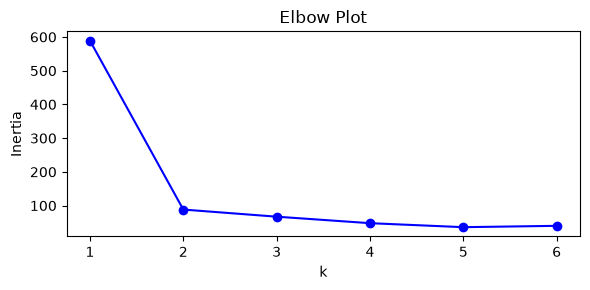

Compare the drop from k=1 to k=2 with the later drops. What would you choose?


In [9]:
def elbow_plot(X, k_range, seed=42):
    inertias = []
    for k in k_range:
        res = kmeans(X, k=k, seed=seed)
        inertias.append(res.inertia)

    plt.figure(figsize=(6, 3))
    plt.plot(list(k_range), inertias, 'bo-')
    plt.xlabel('k'); plt.ylabel('Inertia')
    plt.title('Elbow Plot')
    plt.tight_layout()
    plt.savefig('hw11_elbow.png', dpi=100); plt.show()
    return inertias

inertias = elbow_plot(X_cl, range(1, 7))
print("Compare the drop from k=1 to k=2 with the later drops. What would you choose?")


### 2.2 Supplied demonstration: spectral clustering on two rings

For two centers, the nearest-center boundary is a line. That makes ordinary
k-means a poor match for an inner-ring versus outer-ring grouping. We will
compare it with **spectral clustering**, which first represents points using
eigenvectors of a similarity graph. No new function implementation is required here.

Each point is a graph vertex. For distinct points, the **similarity weight** is
$$W_{ij}=\exp\!\left(-\frac{\|x_i-x_j\|_2^2}{2\sigma^2}\right),\qquad W_{ii}=0.$$
Nearby points have larger weights. The positive parameter `sigma` controls
the distance scale considered nearby; it is not a singular value here.
The degree $d_i=\sum_j W_{ij}$ is the total weight attached to point $i$,
and $D=\operatorname{diag}(d_1,\ldots,d_n)$.

Written homework uses $D-W$. This supplied example uses its **normalized**
version, which rescales by the degrees:
$$L=I-D^{-1/2}WD^{-1/2},\qquad D^{-1/2}_{ii}=1/\sqrt{d_i}.$$
We require positive degrees; if very small `sigma` makes all computed weights
at a point zero, the code asks you to increase it instead of dividing by zero.

Read the supplied steps:
1. Build the `(n,n)` similarity matrix and normalized Laplacian.
2. `np.linalg.eigh` returns eigenvalues in increasing order. Keep the first
   `k` eigenvector columns, including the zero-eigenvalue direction.
3. The resulting `(n,k)` matrix has one row per original point. Normalize
   each nonzero row to unit length (`axis=1`, `keepdims=True`).
4. Run k-means on those **rows**, treating them as new coordinates.

The left panel below shows the groups used to generate the data; those labels
are **not given to either clustering algorithm**. Compare point membership,
not cluster numbers or colors across panels: cluster IDs are arbitrary.


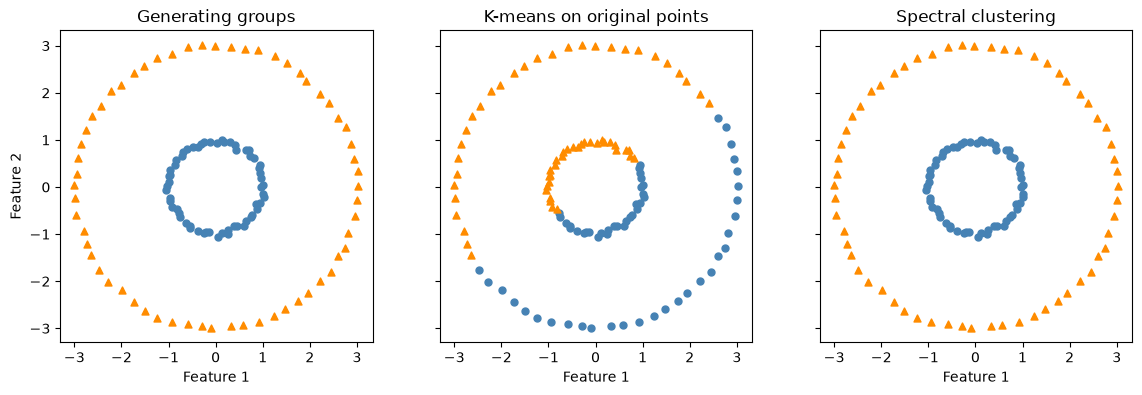

In [10]:
# 2.2 Spectral clustering
def spectral_clustering(X, k, sigma=1.0):
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError("sigma must be positive and finite")
    n = len(X)
    # Step 1: Gaussian similarity matrix
    dists_sq = np.sum((X[:, None, :] - X[None, :, :])**2, axis=2)
    W = np.exp(-dists_sq / (2 * sigma**2))
    np.fill_diagonal(W, 0)

    # Step 2: Normalized Laplacian
    degrees = W.sum(axis=1)
    if np.any(degrees == 0):
        raise ValueError("A point has zero computed degree; try a larger sigma.")
    D_inv_sqrt = np.diag(1.0 / np.sqrt(degrees))
    L = np.eye(n) - D_inv_sqrt @ W @ D_inv_sqrt

    # Step 3: Bottom k eigenvectors (including the zero-eigenvalue direction)
    evals, evecs = np.linalg.eigh(L)
    U = evecs[:, :k]   # (n, k)
    # Normalize rows
    norms = np.linalg.norm(U, axis=1, keepdims=True)
    U /= np.where(norms > 1e-10, norms, 1)

    # Step 4: k-means on U
    return kmeans(U, k)

# Supplied experiment: sample BOTH full circles, with independent noise.
ring_rng = np.random.default_rng(412)
points_per_ring = 60
theta = np.linspace(0, 2*np.pi, points_per_ring, endpoint=False)
unit_circle = np.column_stack([np.cos(theta), np.sin(theta)])
inner_ring = unit_circle + 0.03 * ring_rng.standard_normal((points_per_ring, 2))
outer_ring = 3 * unit_circle + 0.03 * ring_rng.standard_normal((points_per_ring, 2))
X_ring = np.vstack([inner_ring, outer_ring])
ring_groups = np.repeat([0, 1], points_per_ring)  # display only

res_km = kmeans(X_ring, k=2)
res_sp = spectral_clustering(X_ring, k=2, sigma=0.5)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
panel_labels = [ring_groups, res_km.labels, res_sp.labels]
panel_titles = ['Generating groups', 'K-means on original points', 'Spectral clustering']
colors = ['steelblue', 'darkorange']
markers = ['o', '^']
for ax, labels, title in zip(axes, panel_labels, panel_titles):
    for j in range(2):
        points = X_ring[labels == j]
        ax.scatter(points[:, 0], points[:, 1], color=colors[j], marker=markers[j], s=25)
    ax.set_title(title)
    ax.set_xlabel('Feature 1')
    ax.set_aspect('equal')
axes[0].set_ylabel('Feature 2')
plt.tight_layout()
fig.subplots_adjust(top=0.88)
plt.savefig('hw11_spectral.png', dpi=120)
plt.show()


**Interpret the ring comparison (2–3 sentences).** Does each method keep an
entire ring together? Explain how a straight nearest-center boundary differs
from grouping nearby points through a graph. This example illustrates a
useful case, not a guarantee: spectral clustering depends on the chosen
similarities and `sigma`. Its inertia is measured in the new eigenvector
coordinates, so do not compare it numerically with inertia in the original plane.

---
## Part 3: Supplied demonstration — artificial attention patterns

An **attention matrix** has one row per query token and one column per key
token; each nonnegative row sums to 1. The entries are the weights used to
combine value vectors. Here we construct three patterns by hand:
self-focused (large diagonal entries), nearly uniform, and first-token-focused.
These are artificial examples, not attention learned by a trained model.

We flatten each entire `(8,8)` matrix into one row of 64 features. Thus each
data point here is a **whole attention pattern**, not an individual token row.
There are five exact copies of each of the three patterns: 15 rows in total.
The known type labels are created alongside those rows, and are used only
to check the result after clustering.

Cluster IDs such as 0, 1, 2 have no fixed meaning. The supplied comparison
tries all six ways to rename three cluster IDs and reports the best fraction
of matching rows. This is **agreement with our constructed types**, not an
accuracy claim about language or unseen data. You do not need to implement
the renaming code.


In [11]:
# 3.1 Cluster whole artificial attention matrices
n_tok = 8

# Generate 3 "types" of attention patterns:
#   Type 0: peaked (mostly diagonal)
#   Type 1: uniform
#   Type 2: attending to first token
def make_attn_pattern(pattern_type, n):
    rng_p = np.random.default_rng(pattern_type * 100)
    if pattern_type == 0:  # peaked
        A = np.eye(n) * 5 + rng_p.standard_normal((n,n)) * 0.1
    elif pattern_type == 1:  # uniform
        A = np.ones((n,n)) + rng_p.standard_normal((n,n)) * 0.1
    else:  # attend to first
        A = rng_p.standard_normal((n,n)) * 0.1
        A[:, 0] += 5
    def softmax_rows(X):
        X_s = X - X.max(axis=1, keepdims=True)
        e = np.exp(X_s); return e / e.sum(axis=1, keepdims=True)
    return softmax_rows(A)

patterns = [make_attn_pattern(t, n_tok) for t in range(3)]
pattern_rows = []
pattern_types = []
for pattern_type in range(3):
    for copy_number in range(5):
        pattern_rows.append(patterns[pattern_type].reshape(-1))
        pattern_types.append(pattern_type)  # same order as the rows above
X_patterns = np.array(pattern_rows)           # (15, 64)
true_types = np.array(pattern_types)          # (15,)

# Supplied data checks: each matrix has nonnegative rows summing to 1.
assert X_patterns.shape == (15, n_tok * n_tok)
for pattern_type in range(3):
    assert np.all(patterns[pattern_type] >= 0)
    assert np.allclose(patterns[pattern_type].sum(axis=1), 1)
    assert np.allclose(X_patterns[true_types == pattern_type],
                       patterns[pattern_type].reshape(-1))

res_cl = kmeans(X_patterns, k=3)
from itertools import permutations
best_agreement = 0.0
for perm in permutations(range(3)):
    renamed = np.array([perm[label] for label in res_cl.labels])
    agreement = (renamed == true_types).mean()
    best_agreement = max(best_agreement, agreement)
print(f"Agreement with constructed pattern types: {best_agreement:.2%}")


Agreement with constructed pattern types: 100.00%


**Interpret the pattern comparison (1–2 sentences).** Why is grouping exact
copies an easy check? Explain why even perfect agreement here would not show
that a model has learned language.

---
## Part 4: Mini-Transformer Milestone — Cluster Token Embeddings

Cluster the 6 token embeddings with k-means ($k=2$),
visualize in 2D PCA space (from HW 9), and interpret the clusters.


In [12]:
mt_utils.set_seed(412)
E = mt_utils.make_embedding_matrix(6, 8)
vocab = {"[BOS]":0,"the":1,"cat":2,"sat":3,"mat":4,"[EOS]":5}

# Cluster with k=2
res_tok = kmeans(E, k=2)
print("Token cluster assignments:")
for word, idx in vocab.items():
    print(f"  {word}: cluster {res_tok.labels[idx]}")


Token cluster assignments:
  [BOS]: cluster 1
  the: cluster 1
  cat: cluster 0
  sat: cluster 1
  mat: cluster 1
  [EOS]: cluster 1


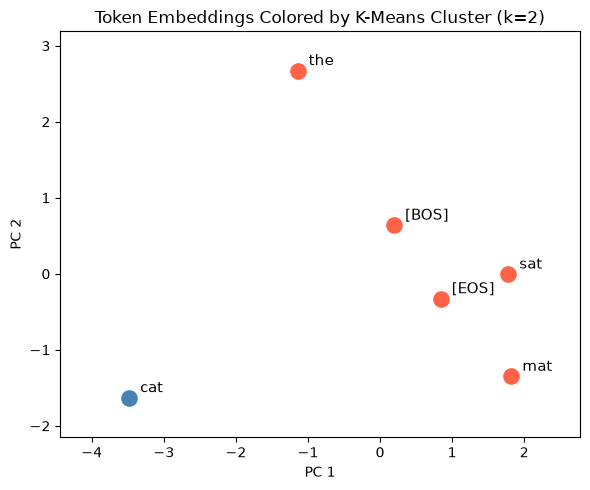

In [13]:
# Visualize in 2D PCA space
# Re-use PCA from HW 9 (copy in if needed, or redefine here)
class PCA:
    def __init__(self, k): self.k=k; self.components=None; self.mean=None
    def fit(self, X):
        self.mean = X.mean(axis=0); Xc = X - self.mean
        evals, evecs = np.linalg.eigh(Xc.T@Xc/(len(X)-1))
        idx = np.argsort(-evals)
        self.components = evecs[:,idx][:,:self.k].T; return self
    def transform(self, X): return (X - self.mean) @ self.components.T
    def fit_transform(self, X): return self.fit(X).transform(X)

pca_tok = PCA(2)
E_2d = pca_tok.fit_transform(E)
colors = ['steelblue', 'tomato']

plt.figure(figsize=(6, 5))
for word, idx in vocab.items():
    c = res_tok.labels[idx]
    plt.scatter(E_2d[idx,0], E_2d[idx,1], color=colors[c], s=120, zorder=3)
    plt.annotate(word, E_2d[idx], xytext=(8,4), textcoords='offset points', fontsize=11)
plt.margins(x=0.18, y=0.12)  # leave room for the token-name labels
plt.xlabel("PC 1"); plt.ylabel("PC 2")
plt.title("Token Embeddings Colored by K-Means Cluster (k=2)")
plt.tight_layout(); plt.savefig('hw11_token_clusters.png', dpi=100); plt.show()


### Your edit: compare two and three clusters

Replace `None` with `kmeans(E, k=3)`. Use the returned object's `.labels` to
color a copy of the PCA scatterplot above; use three colors and retain token
names. Report sizes and compare with `k=2` in 2–3 sentences.
These embeddings were randomly initialized, not trained on language. A
linguistically meaningful grouping is **not** expected; accidental groupings
do not establish learned meaning. Cluster numbers are arbitrary labels.


k=3 cluster sizes: {0: 1, 1: 3, 2: 2}


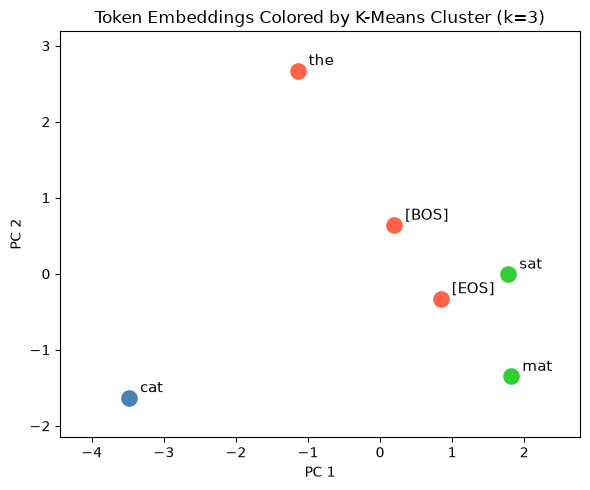

In [14]:
# Try k=3 clusters. Compare sizes and the PCA display with k=2.
# These random vectors have not learned linguistic categories.
k = 3

res_tok3 = kmeans(E, k=3)
if res_tok3 is not None:
    print("k=3 cluster sizes:", res_tok3.cluster_sizes())

    # Plotting code copied from above, extended to 3 colors
    colors = ['steelblue', 'tomato', 'limegreen']

    plt.figure(figsize=(6, 5))
    for word, idx in vocab.items():
        c = res_tok3.labels[idx]
        plt.scatter(E_2d[idx,0], E_2d[idx,1], color=colors[c], s=120, zorder=3)
        plt.annotate(word, E_2d[idx], xytext=(8,4), textcoords='offset points', fontsize=11)
    plt.margins(x=0.18, y=0.12)
    plt.xlabel("PC 1"); plt.ylabel("PC 2")
    plt.title("Token Embeddings Colored by K-Means Cluster (k=3)")
    plt.tight_layout(); plt.savefig('hw11_token_clusters_k3.png', dpi=100); plt.show()


### Project checkpoint: Clustering token features

Group nearby feature rows and count their members. The random embeddings in this lab have not learned word meanings.

1. Download **this assignment's** `student/mini_transformer.py` and keep it
   beside the notebook. In Colab, upload it using the Files panel. It contains
   completed earlier checkpoints, so a missing older submission will not block you.
2. Open the file and search for **THIS WEEK**. Copy your completed cluster_sizes method from the notebook into the matching method below. kmeans and the dataclass structure are supplied.
3. Save the file. Run the reload/check cell below. `mt.name(...)` calls the
   version saved in your module; notebook definitions do not automatically move there.
4. Run the comparison with your notebook result. A match confirms the saved
   component can reproduce that calculation outside the notebook. Explain what
   its input rows and output entries represent in one or two sentences.

Keep `mini_transformer.py` with your project files. **Submit the notebook as
before; this checkpoint adds no graded implementation or extra the course portal file
requirement.** The instructor helper `mt_utils.py` is still read-only. Download
your edited project file before leaving Colab. Model code never belongs in
`mt_utils.py`.

If the companion file is absent, the cell reports **NOT RUN**, not a pass.
This keeps the existing notebook-only grading path independent of the optional
portfolio copy. Download the file and rerun to check your saved project.


In [15]:
import importlib
try:
    import mini_transformer as mt
except ModuleNotFoundError as error:
    if error.name != "mini_transformer":
        raise  # report a genuinely missing dependency inside the file
    print("Project checkpoint NOT RUN: place this assignment's mini_transformer.py beside the notebook.")
    print("This is a portfolio check, separate from the graded notebook tasks.")
else:
    mt = importlib.reload(mt)
    mt.check_milestone()

    project_clusters = mt.kmeans(E, k=2)
    assert np.array_equal(project_clusters.labels, res_tok.labels)
    assert project_clusters.cluster_sizes() == res_tok.cluster_sizes()
    print("Saved project component agrees with the notebook.")


HW11 project checks passed. Continue with the notebook experiment.
Saved project component agrees with the notebook.


### Checklist
- [ ] `cluster_sizes()` passes its assertion, including zero counts for unused centers
- [ ] I examined the elbow curve and explained my choice of `k`
- [ ] I generated `hw11_spectral.png` and explained the ring comparison
- [ ] I recorded attention-pattern agreement and explained the limits of this artificial example
- [ ] I saved the token visualization and compared `k=2` with `k=3`
- [ ] I restarted the runtime and ran the notebook from top to bottom
- [ ] I saved and submitted the completed `.ipynb` notebook through the course portal

**AI-use note:** add a Markdown cell saying which assistant you used, what you
asked, and what you checked or changed. If you did not use one, write “No AI assistance.”

The optional project file remains your own `mini_transformer.py`; it is not
an additional the course portal submission. In Colab, download your edited notebook
and any project file before ending the session.

---
